# Laborator 7
## Inferență Bayesiană cu PyMC: estimarea nivelului de zgomot

### Notații

- $x_1, \dots, x_{10}$: cele $10$ observații ale nivelului de zgomot;
- $\mu$: media (necunoscută) a distribuției zgomotului;
- $\sigma$: deviația standard (necunoscută), $\sigma > 0$;
- $\bar{x}$: media empirică a observațiilor, media priorului pe $\mu$;
- HDI 95%: intervalul de cea mai mare densitate a posteriori care conține $95\%$ din masa de probabilitate.

## a) Modelul PyMC

$$\mu \sim \mathcal{N}(\bar{x},\ 10^2), \qquad \sigma \sim \text{HalfNormal}(10).$$

Media priorului pe $\mu$ trebuie centrată pentru nivelul de zgomot. Alegem media empirică a observațiilor:

$$\bar{x} = 58\ \text{dB}.$$

In [ ]:
import numpy as np
import pymc as pm
import arviz as az

# cele 10 observatii ale nivelului de zgomot (dB)
date = np.array([56, 60, 58, 55, 57, 59, 61, 56, 58, 60], dtype=float)
x_bar = date.mean()  # media empirica -> media priorului pe mu
print(f"numar observatii = {date.size}")
print(f"media empirica x_bar = {x_bar:.1f} dB")
print(f"deviatie standard empirica = {date.std(ddof=1):.2f} dB")

with pm.Model() as model:
    mu = pm.Normal("mu", mu=x_bar, sigma=10)       # prior N(x_bar, 10^2)
    sigma = pm.HalfNormal("sigma", sigma=10)       # prior HalfNormal(10), sigma > 0
    x = pm.Normal("x", mu=mu, sigma=sigma, observed=date)  # verosimilitate normala


numar observatii = 10
media empirica x_bar = 58.0 dB
deviatie standard empirica = 2.00 dB


## b) Inferența asupra lui $\mu$ și $\sigma$

In [2]:
with model:
    idata = pm.sample(2000, tune=1000, chains=4, random_seed=42,
                      progressbar=False)

# rezumat: media, deviatia si intervalul a posteriori
rezumat = az.summary(idata, ci_prob=0.95, kind="stats")
print(rezumat)


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu, sigma]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 0 seconds.


      mean    sd eti95_lb eti95_ub
mu      58  0.77       56       60
sigma  2.3  0.67      1.4        4


In [3]:
# intervalul de incredere (HDI 95%) pentru mu si sigma
hdi = az.hdi(idata, prob=0.95)
hdi_mu = hdi["mu"].values
hdi_sigma = hdi["sigma"].values

mu_mean = idata.posterior["mu"].mean().item()
sigma_mean = idata.posterior["sigma"].mean().item()

print(f"mu:    medie = {mu_mean:.2f} dB,  HDI 95% = [{hdi_mu[0]:.2f}, {hdi_mu[1]:.2f}] dB")
print(f"sigma: medie = {sigma_mean:.2f} dB,  HDI 95% = [{hdi_sigma[0]:.2f}, {hdi_sigma[1]:.2f}] dB")


mu:    medie = 58.00 dB,  HDI 95% = [56.46, 59.54] dB
sigma: medie = 2.33 dB,  HDI 95% = [1.32, 3.67] dB


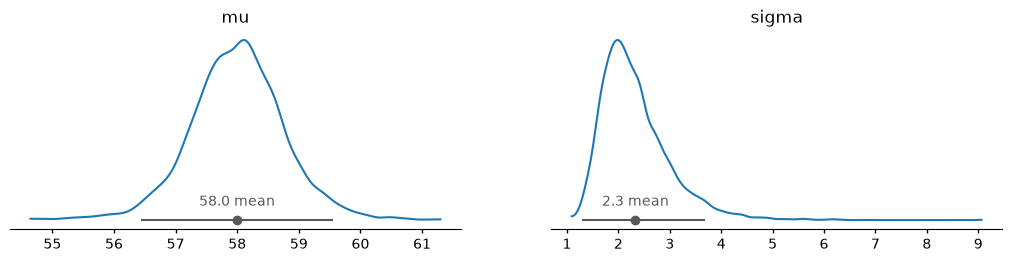

In [4]:
# vizualizarea posteriorilor cu intervalul de credibilitate 95% (HDI)
az.plot_dist(idata, var_names=["mu", "sigma"],
             point_estimate="mean", ci_prob=0.95, ci_kind="hdi")


Posteriorul pentru media zgomotului este centrat pe $\approx 58$ dB, cu HDI 95% de aproximativ $[56.5,\ 59.5]$ dB. Deviația standard are media a posteriori $\approx 2.3$ dB, cu HDI 95% în jur de $[1.3,\ 3.7]$ dB.

Priorul este slab informativ (deviație $10$ dB, mai mare decât a datelor), așa că posteriorul este influențat de observații: media a posteriori a lui $\mu$ este egală cu $\bar{x}=58$ dB.